# Notebook 06 — Exploratory Ward Anomaly Detection

## Roadmap
Phase 6 — Unsupervised Learning & Anomaly Detection.

## Objective
Identify unusual combinations of search volume, booking conversion,
and booking completion for further investigation.

## Existing work
Earlier notebooks checked booking–ride inconsistencies, screened
conversion outliers using IQR, and investigated w_0 driver counts.
We will reference those findings rather than repeat them.

## Approach
Evaluate Isolation Forest using demand-and-funnel features.
Review rankings alongside search and booking counts, and assess
sensitivity to model settings.

## Interpretation
Anomalies are investigation candidates, not proof of errors,
fraud, driver shortages, or poor performance.
No records will be removed automatically.

In [1]:
from pathlib import Path
import subprocess
import pandas as pd

# Set up the repository if it is not already available.
PROJECT_DIR = Path("/content/NammaFlow")

if not PROJECT_DIR.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Narasimhan15/NammaFlow.git",
            str(PROJECT_DIR),
        ],
        check=True,
    )

DATA_PATH = PROJECT_DIR / "data" / "features" / "ward_intelligence.csv"

if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Dataset not found: {DATA_PATH}")

ward_data = pd.read_csv(DATA_PATH)

print(f"Dataset: {DATA_PATH}")
print(f"Rows: {ward_data.shape[0]} | Columns: {ward_data.shape[1]}")

print("\nColumn names:")
print(ward_data.columns.tolist())

display(ward_data.head())

print("\nData types and missing values:")
display(
    pd.DataFrame({
        "dtype": ward_data.dtypes.astype(str),
        "missing_count": ward_data.isna().sum(),
    })
)

Dataset: /content/NammaFlow/data/features/ward_intelligence.csv
Rows: 244 | Columns: 65

Column names:
['ward_num', 'ward_searches', 'ward_searches_got_e', 'ward_q_requests', 'ward_q_received', 'ward_search_to_e_rate', 'ward_e_to_q_request_rate', 'ward_q_accept_rate', 'ward_search_to_q_request_rate', 'ward_search_to_q_received_rate', 'ward_q_supply_gap', 'ward_q_supply_gap_rate', 'ward_search_to_q_received_gap', 'ward_bookings', 'ward_rides', 'ward_completed_rides', 'ward_cancellations', 'ward_driver_cancellations', 'ward_rider_cancellations', 'ward_earnings', 'ward_booking_to_ride_rate', 'ward_ride_completion_rate', 'ward_booking_completion_rate', 'ward_cancel_per_booking', 'ward_other_cancellations', 'ward_driver_cancel_share', 'ward_rider_cancel_share', 'ward_other_cancel_share', 'ward_earning_per_ride', 'ward_earning_per_completed_ride', 'ward_booking_to_ride_gap', 'ward_ride_completion_gap', 'ward_booking_to_completion_gap', 'ward_ride_booking_mismatch', 'supply_vehicle_coverage',

,ward_num,ward_searches,ward_searches_got_e,ward_q_requests,ward_q_received,ward_search_to_e_rate,ward_e_to_q_request_rate,ward_q_accept_rate,ward_search_to_q_request_rate,ward_search_to_q_received_rate,...,searches_per_notonride_driver,q_requests_per_notonride_driver,q_supply_gap_per_notonride_driver,pre_q_loss_rate,q_to_booking_loss_rate,booking_to_completion_loss_rate,overall_search_completion_loss_rate,capacity_pressure_score,allocation_pressure_score,pressure_score_sum
0,b_1,72,72,39,21,1.0,0.541667,0.538462,0.541667,0.291667,...,0.230032,0.124601,0.057508,0.708333,0.095238,0.368421,0.833333,0.031593,0.429945,0.461538
1,b_10,188,188,139,65,1.0,0.739362,0.467626,0.739362,0.345745,...,0.471178,0.348371,0.185464,0.654255,0.000000,0.507692,0.829787,0.099752,0.432622,0.532374
2,b_100,159,159,129,56,1.0,0.811321,0.434109,0.811321,0.352201,...,0.732719,0.594470,0.336406,0.647799,0.000000,0.339286,0.767296,0.152429,0.413463,0.565891
3,b_101,43,43,29,19,1.0,0.674419,0.655172,0.674419,0.441860,...,0.716667,0.483333,0.166667,0.558140,0.000000,0.736842,0.883721,0.104250,0.240577,0.344828
4,b_102,127,127,110,52,1.0,0.866142,0.472727,0.866142,0.409449,...,1.984375,1.718750,0.906250,0.590551,0.038462,0.540000,0.818898,0.139394,0.387879,0.527273



Data types and missing values:


,dtype,missing_count
ward_num,object,0
ward_searches,int64,0
ward_searches_got_e,int64,0
ward_q_requests,int64,0
ward_q_received,int64,0
...,...,...
booking_to_completion_loss_rate,float64,3
overall_search_completion_loss_rate,float64,0
capacity_pressure_score,float64,3
allocation_pressure_score,float64,3


## 6.1 — Validate Inputs and Identify Eligible Records

Use search volume, search-to-booking conversion, and booking completion,
consistent with the earlier clustering analysis.

Check record identifiers, numeric values, denominators, and rate consistency.
Preserve excluded records separately without imputing undefined rates.

Driver-supply features are excluded because their temporal compatibility
with demand remains unverified. Keep w_0 identifiable for sensitivity analysis.

In [2]:
import numpy as np

CHECK_COLS = [
    "ward_searches",
    "ward_bookings",
    "ward_completed_rides",
    "ward_search_to_booking_rate",
    "ward_booking_completion_rate",
]

assert ward_data["ward_num"].notna().all(), "Missing record identifiers."
assert ward_data["ward_num"].is_unique, "Duplicate record identifiers."

# Validate numeric inputs without changing the original dataset.
checked = ward_data[CHECK_COLS].apply(pd.to_numeric, errors="raise")

print("Input summary:")
display(pd.DataFrame({
    "missing": checked.isna().sum(),
    "infinite": np.isinf(checked).sum(),
    "minimum": checked.min(),
    "maximum": checked.max(),
}))

count_cols = [
    "ward_searches",
    "ward_bookings",
    "ward_completed_rides",
]

assert np.isfinite(checked[count_cols]).all().all(), \
    "Missing or infinite counts: investigate before continuing."
assert checked[count_cols].ge(0).all().all(), \
    "Negative counts: investigate before continuing."

# Check saved rates against their underlying counts.
expected_conversion = (
    checked["ward_bookings"]
    / checked["ward_searches"].replace(0, np.nan)
)
expected_completion = (
    checked["ward_completed_rides"]
    / checked["ward_bookings"].replace(0, np.nan)
)

for column, expected in [
    ("ward_search_to_booking_rate", expected_conversion),
    ("ward_booking_completion_rate", expected_completion),
]:
    matches = np.isclose(
        checked[column], expected,
        rtol=1e-6, atol=1e-8, equal_nan=True,
    )
    assert matches.all(), f"Saved rate does not match counts: {column}"

# Keep a reason for every exclusion.
reasons = pd.DataFrame({
    "nonpositive_searches": checked["ward_searches"].le(0),
    "nonpositive_bookings": checked["ward_bookings"].le(0),
    "missing_or_nonfinite_input": ~np.isfinite(checked).all(axis=1),
})

eligible_mask = ~reasons.any(axis=1)

anomaly_eligible = ward_data.loc[eligible_mask].copy()
anomaly_excluded = ward_data.loc[~eligible_mask].copy()

anomaly_excluded["exclusion_reason"] = reasons.loc[
    ~eligible_mask
].apply(
    lambda row: "; ".join(row.index[row]),
    axis=1,
)

print(f"Total records: {len(ward_data)}")
print(f"Eligible: {len(anomaly_eligible)}")
print(f"Excluded from model fitting: {len(anomaly_excluded)}")

display(
    anomaly_excluded[
        ["ward_num"] + CHECK_COLS + ["exclusion_reason"]
    ]
)

print("w_0 input values:")
display(
    ward_data.loc[
        ward_data["ward_num"].eq("w_0"),
        ["ward_num"] + CHECK_COLS,
    ]
)

Input summary:


,missing,infinite,minimum,maximum
ward_searches,0,0,2.0,4862.00
ward_bookings,0,0,0.0,776.00
ward_completed_rides,0,0,0.0,370.00
ward_search_to_booking_rate,0,0,0.0,0.76
ward_booking_completion_rate,3,0,0.0,1.00


Total records: 244
Eligible: 241
Excluded from model fitting: 3


,ward_num,ward_searches,ward_bookings,ward_completed_rides,ward_search_to_booking_rate,ward_booking_completion_rate,exclusion_reason
76,b_168,13,0,0,0.0,NaN,nonpositive_bookings; missing_or_nonfinite_input
162,b_26,8,0,0,0.0,NaN,nonpositive_bookings; missing_or_nonfinite_input
182,b_44,2,0,0,0.0,NaN,nonpositive_bookings; missing_or_nonfinite_input


w_0 input values:


,ward_num,ward_searches,ward_bookings,ward_completed_rides,ward_search_to_booking_rate,ward_booking_completion_rate
243,w_0,3460,776,370,0.224277,0.476804


## 6.2 — Prepare Anomaly-Detection Features

Use:
- log1p(search volume), to reduce skew in demand counts;
- search-to-booking conversion;
- booking completion rate.

Identifiers and driver-supply variables are not model inputs.
Keep raw counts alongside the features for interpretation.

Low-booking records remain eligible, but their rates require caution.
Their influence will be assessed in sensitivity analysis.

In [3]:
# Build features independently of the clustering notebook.
anomaly_features = pd.DataFrame(
    {
        "log1p_ward_searches": np.log1p(
            anomaly_eligible["ward_searches"]
        ),
        "ward_search_to_booking_rate":
            anomaly_eligible["ward_search_to_booking_rate"],
        "ward_booking_completion_rate":
            anomaly_eligible["ward_booking_completion_rate"],
    },
    index=anomaly_eligible.index,
)

FEATURE_ORDER = anomaly_features.columns.tolist()

assert anomaly_features.index.equals(anomaly_eligible.index)
assert np.isfinite(anomaly_features).all().all()
assert anomaly_features.nunique().gt(1).all()

# Context flag only; this is not a model input or exclusion rule.
anomaly_eligible["low_booking_count"] = (
    anomaly_eligible["ward_bookings"] < 10
)

print(f"Feature matrix: {anomaly_features.shape}")
print("Feature order:", FEATURE_ORDER)

print("\nFeature summary:")
display(anomaly_features.describe().round(4))

print("\nBooking-count context:")
print(
    anomaly_eligible["low_booking_count"]
    .value_counts()
    .rename_axis("fewer_than_10_bookings")
    .to_string()
)

print("\nFeature preview with identifiers:")
display(
    anomaly_eligible[["ward_num", "ward_bookings"]]
    .join(anomaly_features)
    .head()
)

Feature matrix: (241, 3)
Feature order: ['log1p_ward_searches', 'ward_search_to_booking_rate', 'ward_booking_completion_rate']

Feature summary:


,log1p_ward_searches,ward_search_to_booking_rate,ward_booking_completion_rate
count,241.0000,241.0000,241.0000
mean,4.0808,0.3431,0.5351
std,1.1924,0.1075,0.1851
min,1.3863,0.1053,0.0000
25%,3.3322,0.2727,0.4355
50%,3.9120,0.3333,0.5156
75%,4.7958,0.4070,0.6250
max,8.4894,0.7600,1.0000



Booking-count context:
fewer_than_10_bookings
False    174
True      67

Feature preview with identifiers:


,ward_num,ward_bookings,log1p_ward_searches,ward_search_to_booking_rate,ward_booking_completion_rate
0,b_1,19,4.290459,0.263889,0.631579
1,b_10,65,5.241747,0.345745,0.492308
2,b_100,56,5.075174,0.352201,0.660714
3,b_101,19,3.784190,0.441860,0.263158
4,b_102,50,4.852030,0.393701,0.460000


## 6.3 — Fit an Exploratory Isolation Forest

Fit Isolation Forest using the three prepared features.

Use a fixed random seed for reproducibility. Rank records by the
negative of score_samples, so higher scores indicate greater unusualness.

Review the top 15 as an exploratory inspection shortlist.
This shortlist does not estimate anomaly prevalence, and the scores
are not probabilities. No records are removed.

These are descriptive scores on the fitted dataset; they do not
measure predictive performance on future records.

In [4]:
import sklearn
from sklearn.ensemble import IsolationForest

MODEL_SETTINGS = {
    "n_estimators": 500,
    "max_samples": 128,
    "contamination": "auto",
    "max_features": 1.0,
    "bootstrap": False,
    "random_state": 42,
    "n_jobs": -1,
}

isolation_model = IsolationForest(**MODEL_SETTINGS)

X_anomaly = anomaly_features[FEATURE_ORDER].copy()
isolation_model.fit(X_anomaly)

anomaly_results = anomaly_eligible.copy()

# Higher score = more unusual under this fitted model.
anomaly_results["anomaly_score"] = (
    -isolation_model.score_samples(X_anomaly)
)

assert np.isfinite(anomaly_results["anomaly_score"]).all()

anomaly_results = anomaly_results.sort_values(
    ["anomaly_score", "ward_num"],
    ascending=[False, True],
).copy()

anomaly_results["review_position"] = np.arange(
    1, len(anomaly_results) + 1
)

REVIEW_COLS = [
    "review_position",
    "ward_num",
    "anomaly_score",
    "ward_searches",
    "ward_bookings",
    "ward_completed_rides",
    "ward_search_to_booking_rate",
    "ward_booking_completion_rate",
    "low_booking_count",
]

print("scikit-learn version:", sklearn.__version__)
print("Model settings:", MODEL_SETTINGS)

print("\nAnomaly-score summary:")
display(anomaly_results["anomaly_score"].describe().round(4))

print("\nTop 15 records for exploratory review:")
display(anomaly_results[REVIEW_COLS].head(15).round(4))

print(
    "\nLow-booking records in top 15:",
    int(anomaly_results.head(15)["low_booking_count"].sum()),
)

print("\nw_0 review position:")
display(
    anomaly_results.loc[
        anomaly_results["ward_num"].eq("w_0"),
        REVIEW_COLS,
    ].round(4)
)

scikit-learn version: 1.6.1
Model settings: {'n_estimators': 500, 'max_samples': 128, 'contamination': 'auto', 'max_features': 1.0, 'bootstrap': False, 'random_state': 42, 'n_jobs': -1}

Anomaly-score summary:


,anomaly_score
count,241.0000
mean,0.4537
std,0.0613
min,0.3788
25%,0.4092
50%,0.4378
75%,0.4807
max,0.6773



Top 15 records for exploratory review:


,review_position,ward_num,anomaly_score,ward_searches,ward_bookings,ward_completed_rides,ward_search_to_booking_rate,ward_booking_completion_rate,low_booking_count
91,1,b_181,0.6773,4862,556,216,0.1144,0.3885,False
180,2,b_42,0.6684,5,1,0,0.2000,0.0000,True
145,3,b_23,0.6365,9,1,1,0.1111,1.0000,True
193,4,b_54,0.6194,3,1,1,0.3333,1.0000,True
183,5,b_45,0.6177,11,3,0,0.2727,0.0000,True
63,6,b_156,0.6176,4,1,1,0.2500,1.0000,True
61,7,b_154,0.6141,13,3,0,0.2308,0.0000,True
159,8,b_242,0.6024,26,4,4,0.1538,1.0000,True
42,9,b_137,0.5954,27,6,0,0.2222,0.0000,True
97,10,b_187,0.5923,1874,440,141,0.2348,0.3205,False



Low-booking records in top 15: 10

w_0 review position:


,review_position,ward_num,anomaly_score,ward_searches,ward_bookings,ward_completed_rides,ward_search_to_booking_rate,ward_booking_completion_rate,low_booking_count
243,12,w_0,0.5891,3460,776,370,0.2243,0.4768,False


**Isolation Forest** is an unsupervised algorithm that identifies unusual records by repeatedly splitting data using randomly selected features and split points. Unusual records tend to be isolated in fewer splits.

Why we’re using it in NammaFlow:
- We don’t have labelled examples of anomalous wards.
- It can detect unusual combinations of search volume, booking conversion, and completion rate that individual outlier checks may miss.
- It gives us a ranking of records for further investigation.
Its scores indicate unusualness—not proof of errors or poor performance. We’ll check ranking stability and review booking counts before drawing conclusions.

## 6.4 — Check Ranking Sensitivity to Model Settings

Compare the initial ranking with models using different random seeds
and per-tree sample sizes.

Measure:
- Spearman correlation across all record scores;
- overlap with the initial top-15 shortlist.

These checks assess consistency, not detection accuracy.
The top 15 remains an exploratory review size.

In [5]:
# Align baseline scores with the original feature-matrix order.
baseline_scores = anomaly_results["anomaly_score"].reindex(
    X_anomaly.index
)

def top_review_indices(scores, n=15):
    table = pd.DataFrame({
        "score": scores,
        "ward_num": anomaly_eligible.loc[scores.index, "ward_num"],
    })
    return table.sort_values(
        ["score", "ward_num"],
        ascending=[False, True],
    ).head(n).index

baseline_top15 = set(top_review_indices(baseline_scores))

sensitivity_rows = []

for max_samples in [64, 128, len(X_anomaly)]:
    for seed in [7, 21, 42]:
        settings = {
            **MODEL_SETTINGS,
            "max_samples": max_samples,
            "random_state": seed,
        }

        candidate = IsolationForest(**settings)
        candidate.fit(X_anomaly)

        scores = pd.Series(
            -candidate.score_samples(X_anomaly),
            index=X_anomaly.index,
        )

        candidate_top15 = set(top_review_indices(scores))
        overlap = len(baseline_top15 & candidate_top15)

        sensitivity_rows.append({
            "max_samples": max_samples,
            "seed": seed,
            "spearman_vs_baseline": baseline_scores.corr(
                scores, method="spearman"
            ),
            "top15_overlap_count": overlap,
            "top15_overlap_fraction": overlap / 15,
        })

model_sensitivity = pd.DataFrame(sensitivity_rows)

display(model_sensitivity.round(4))

,max_samples,seed,spearman_vs_baseline,top15_overlap_count,top15_overlap_fraction
0,64,7,0.9918,13,0.8667
1,64,21,0.9891,14,0.9333
2,64,42,0.9946,14,0.9333
3,128,7,0.9942,15,1.0000
4,128,21,0.9941,15,1.0000
5,128,42,1.0000,15,1.0000
6,241,7,0.9935,14,0.9333
7,241,21,0.9952,14,0.9333
8,241,42,0.9941,15,1.0000


The rankings are consistent across the settings tested:
- Excluding the baseline’s self-comparison, Spearman correlation ranges from 0.9891 to 0.9952.
- Each model retains 13–15 of the original top 15 records.
- At max_samples=128, all three seeds produce the same shortlist, although ordering can differ.
This supports consistency under these settings; it doesn’t establish detection accuracy.

## 6.5 — Assess Sensitivity to Record Eligibility

Refit the baseline model in two scenarios:
1. Keep only records with at least 10 bookings.
2. Exclude w_0, whose geographic meaning remains unresolved.

Compare rankings on the records shared by the baseline and each scenario.
For each comparison, first restrict baseline scores to those same records,
then calculate rank correlation and top-15 overlap.

The 10-booking cutoff is an exploratory sensitivity choice, not a
validated reliability threshold. Original records and results are preserved.

In [6]:
scenario_masks = {
    "at_least_10_bookings":
        anomaly_eligible["ward_bookings"].ge(10),
    "without_w_0":
        anomaly_eligible["ward_num"].ne("w_0"),
}

eligibility_rows = []
scenario_rankings = {}

for scenario, mask in scenario_masks.items():
    scenario_X = X_anomaly.loc[mask].copy()

    scenario_model = IsolationForest(**MODEL_SETTINGS)
    scenario_model.fit(scenario_X)

    scenario_scores = pd.Series(
        -scenario_model.score_samples(scenario_X),
        index=scenario_X.index,
    )

    # Compare both rankings on exactly the same records.
    shared_baseline = baseline_scores.loc[scenario_X.index]

    baseline_top = set(top_review_indices(shared_baseline))
    scenario_top = set(top_review_indices(scenario_scores))

    eligibility_rows.append({
        "scenario": scenario,
        "records": len(scenario_X),
        "spearman_on_shared_records": shared_baseline.corr(
            scenario_scores, method="spearman"
        ),
        "top15_overlap_on_shared_records":
            len(baseline_top & scenario_top),
    })

    ranking = anomaly_eligible.loc[scenario_X.index].copy()
    ranking["scenario_score"] = scenario_scores
    ranking = ranking.sort_values(
        ["scenario_score", "ward_num"],
        ascending=[False, True],
    )
    ranking["scenario_position"] = np.arange(1, len(ranking) + 1)
    scenario_rankings[scenario] = ranking

eligibility_sensitivity = pd.DataFrame(eligibility_rows)

print("Sensitivity summary:")
display(eligibility_sensitivity.round(4))

print("\nTop 15 after restricting to at least 10 bookings:")
display(
    scenario_rankings["at_least_10_bookings"][
        [
            "scenario_position",
            "ward_num",
            "scenario_score",
            "ward_searches",
            "ward_bookings",
            "ward_search_to_booking_rate",
            "ward_booking_completion_rate",
        ]
    ].head(15).round(4)
)

Sensitivity summary:


,scenario,records,spearman_on_shared_records,top15_overlap_on_shared_records
0,at_least_10_bookings,174,0.9227,11
1,without_w_0,240,0.9953,14



Top 15 after restricting to at least 10 bookings:


,scenario_position,ward_num,scenario_score,ward_searches,ward_bookings,ward_search_to_booking_rate,ward_booking_completion_rate
91,1,b_181,0.7128,4862,556,0.1144,0.3885
49,2,b_143,0.6371,25,19,0.7600,0.6316
196,3,b_57,0.6232,16,10,0.6250,0.4000
243,4,w_0,0.6169,3460,776,0.2243,0.4768
45,5,b_14,0.6159,31,20,0.6452,0.3000
97,6,b_187,0.6139,1874,440,0.2348,0.3205
46,7,b_140,0.5912,42,10,0.2381,0.2000
131,8,b_217,0.5895,21,12,0.5714,0.3333
36,9,b_131,0.5890,516,69,0.1337,0.4203
57,10,b_150,0.5853,28,12,0.4286,0.8333


## 6.6 — Visualise the Exploratory Shortlist

Plot search volume against booking conversion and completion.
Highlight the initial top-15 shortlist and identify low-booking records.

These plots describe observed feature patterns; they do not explain
the model's feature contributions or establish causes.

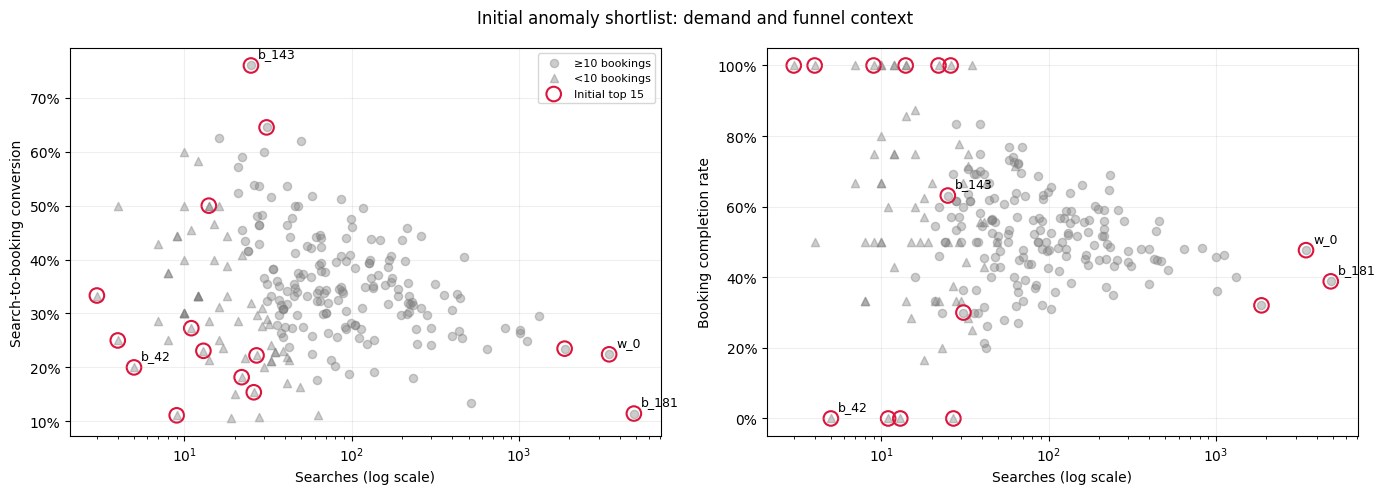

In [7]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plot_data = anomaly_results.copy()
shortlist_mask = plot_data["review_position"].le(15)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_specs = [
    ("ward_search_to_booking_rate", "Search-to-booking conversion"),
    ("ward_booking_completion_rate", "Booking completion rate"),
]

for ax, (column, label) in zip(axes, plot_specs):
    for low_count, marker in [(False, "o"), (True, "^")]:
        group = plot_data["low_booking_count"].eq(low_count)

        ax.scatter(
            plot_data.loc[group, "ward_searches"],
            plot_data.loc[group, column],
            marker=marker,
            color="grey",
            alpha=0.4,
            s=35,
            label="<10 bookings" if low_count else "≥10 bookings",
        )

    ax.scatter(
        plot_data.loc[shortlist_mask, "ward_searches"],
        plot_data.loc[shortlist_mask, column],
        facecolors="none",
        edgecolors="crimson",
        linewidths=1.5,
        s=110,
        label="Initial top 15",
    )

    for ward in ["b_181", "b_42", "b_143", "w_0"]:
        row = plot_data.loc[plot_data["ward_num"].eq(ward)]
        if not row.empty:
            ax.annotate(
                ward,
                (row["ward_searches"].iloc[0], row[column].iloc[0]),
                xytext=(5, 6),
                textcoords="offset points",
                fontsize=9,
            )

    ax.set_xscale("log")
    ax.set_xlabel("Searches (log scale)")
    ax.set_ylabel(label)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.2)

axes[0].legend(fontsize=8)
fig.suptitle("Initial anomaly shortlist: demand and funnel context")
plt.tight_layout()
plt.show()

**6.7 — Findings and Limitations**

Isolation Forest ranked 241 eligible records using log-transformed search
volume, booking conversion, and booking completion. Three zero-booking
records were preserved separately because completion rates were undefined.

**Main findings**
- b_181 ranked first in both the initial model and the ≥10-bookings
  scenario. It combines 4,862 searches with 11.44% booking conversion
  and 38.85% booking completion.
- Ten of the initial top 15 records had fewer than 10 bookings.
  Several had 0% or 100% completion, requiring small-count caution.
- b_143 had unusually high observed booking conversion (76%),
  based on 25 searches and 19 bookings.
- w_0 ranked 12th initially, but its geographic meaning remains unresolved.

**Sensitivity**
- Across alternative seeds and sample sizes, rank correlations with the
  baseline ranged from 0.9891 to 0.9952, excluding self-comparison.
  Top-15 overlap ranged from 13 to 15 records.
- Restricting to ≥10 bookings produced correlation 0.9227 and
  top-15 overlap 11/15, comparing rankings on the same 174 records.
- Excluding w_0 produced correlation 0.9953 and top-15 overlap 14/15
  on the remaining 240 records.

**Interpretation**

Retain the initial ranking as an exploratory investigation aid.
Review scores alongside counts and sensitivity results.

Ranking consistency does not establish detection accuracy.
No labelled anomalies were available, the top-15 review size is arbitrary,
and the 10-booking cutoff is not a validated reliability threshold.
Scores are not probabilities or evidence of operational causes.
No records were automatically removed or assigned interventions.

In [8]:
import hashlib
import json
import platform
import joblib

REPORT_DIR = PROJECT_DIR / "reports" / "anomaly_detection"
MODEL_DIR = PROJECT_DIR / "models"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

anomaly_results.to_csv(REPORT_DIR / "ward_anomaly_rankings.csv", index=False)
anomaly_excluded.to_csv(REPORT_DIR / "excluded_records.csv", index=False)

anomaly_features.rename_axis("source_row_index").to_csv(
    REPORT_DIR / "model_features.csv"
)

model_sensitivity.to_csv(
    REPORT_DIR / "model_setting_sensitivity.csv", index=False
)
eligibility_sensitivity.to_csv(
    REPORT_DIR / "eligibility_sensitivity.csv", index=False
)

for name, ranking in scenario_rankings.items():
    ranking.to_csv(REPORT_DIR / f"ranking_{name}.csv", index=False)

fig.savefig(
    REPORT_DIR / "anomaly_shortlist.png",
    dpi=200,
    bbox_inches="tight",
)

metadata = {
    "feature_order": FEATURE_ORDER,
    "transformation": "log1p(ward_searches); other two features unchanged",
    "score_definition": "-IsolationForest.score_samples; higher is more unusual",
    "model_settings": MODEL_SETTINGS,
    "eligible_records": len(anomaly_eligible),
    "excluded_records": len(anomaly_excluded),
    "review_size": 15,
    "review_size_is_exploratory": True,
    "data_sha256": hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    "versions": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_learn": sklearn.__version__,
        "joblib": joblib.__version__,
    },
}

(REPORT_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

MODEL_PATH = MODEL_DIR / "ward_isolation_forest_exploratory.joblib"

joblib.dump(
    {"model": isolation_model, "metadata": metadata},
    MODEL_PATH,
)

# Reload only the artifact we just created.
restored = joblib.load(MODEL_PATH)
restored_scores = -restored["model"].score_samples(
    X_anomaly[restored["metadata"]["feature_order"]]
)

np.testing.assert_allclose(
    restored_scores,
    baseline_scores.to_numpy(),
    rtol=1e-12,
    atol=1e-12,
)

print("Reloaded model scores match.")
print("Model saved:", MODEL_PATH)
print("Reports saved:", REPORT_DIR)
print("\nReport files:")
for path in sorted(REPORT_DIR.iterdir()):
    if path.is_file():
        print(" -", path.name)

Reloaded model scores match.
Model saved: /content/NammaFlow/models/ward_isolation_forest_exploratory.joblib
Reports saved: /content/NammaFlow/reports/anomaly_detection

Report files:
 - anomaly_shortlist.png
 - eligibility_sensitivity.csv
 - excluded_records.csv
 - metadata.json
 - model_features.csv
 - model_setting_sensitivity.csv
 - ranking_at_least_10_bookings.csv
 - ranking_without_w_0.csv
 - ward_anomaly_rankings.csv


In [9]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

ZIP_PATH = Path("/content/NammaFlow_anomaly_checkpoint.zip")

artifact_paths = [MODEL_PATH] + sorted(
    path for path in REPORT_DIR.iterdir() if path.is_file()
)

with ZipFile(ZIP_PATH, "w", compression=ZIP_DEFLATED) as archive:
    for path in artifact_paths:
        archive.write(
            path,
            arcname=str(path.relative_to(PROJECT_DIR)),
        )

with ZipFile(ZIP_PATH) as archive:
    assert archive.testzip() is None, "ZIP integrity check failed."
    print(f"Verified archive: {len(archive.namelist())} files")

files.download(str(ZIP_PATH))

Verified archive: 10 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>